⏳ Đang tải dữ liệu PAXGUSDT khung 15m...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...

     Final Equity: 5535.5301
     Total Return: -0.4464
    CAGR (approx): -0.4237
     Max Drawdown: -0.7871
           Sharpe: -0.6540
           Trades: 2318
          Winrate: 0.4047
    Avg PnL/Trade: -1.9289
    Profit Factor: 0.9121


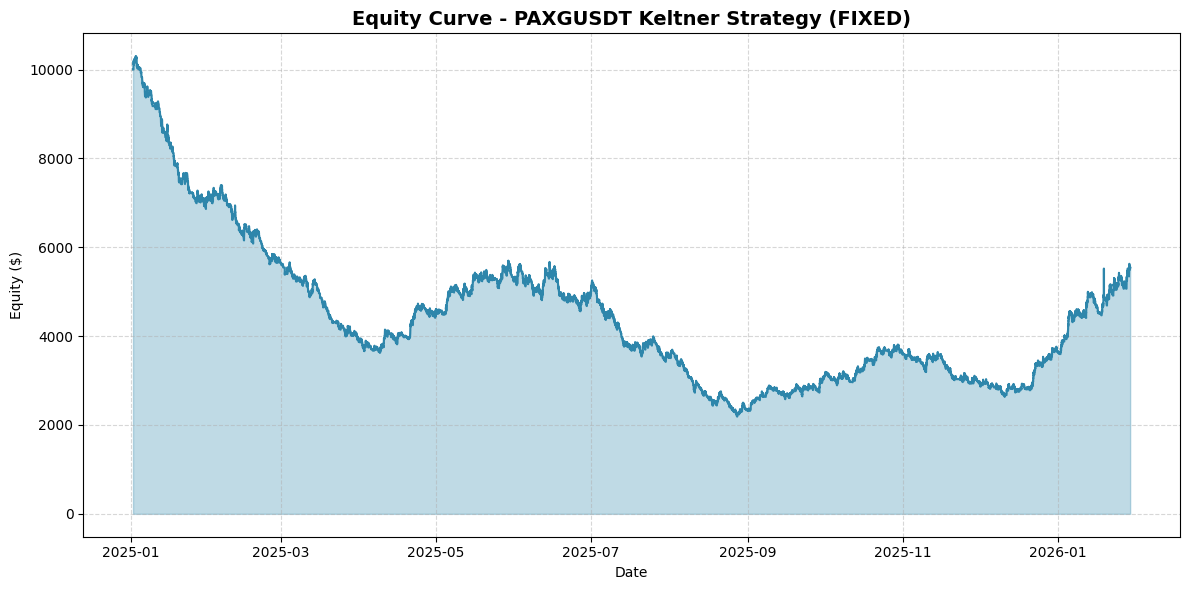


📊 Sample Trades (first 10):
               Exit Time  Type        Entry         Exit         PnL       Reason      Balance
2308 2026-01-28 07:45:00  LONG  5274.710000  5304.740000   68.888807    Time Exit  5508.523704
2309 2026-01-28 09:15:00  LONG  5315.400000  5293.277927  -55.085237    Stop Loss  5453.438467
2310 2026-01-28 15:15:00  LONG  5313.632605  5288.327803  -54.534385    Stop Loss  5398.904082
2311 2026-01-28 18:30:00  LONG  5322.087905  5294.615689  -53.989041    Stop Loss  5344.915041
2312 2026-01-28 20:30:00  LONG  5338.501131  5396.299243  106.898301  Take Profit  5451.813342
2313 2026-01-28 23:00:00  LONG  5398.760000  5466.419771  109.036267  Take Profit  5560.849609
2314 2026-01-29 00:00:00  LONG  5510.120000  5505.685846   -7.198263    Stop Loss  5553.651346
2315 2026-01-29 01:00:00  LONG  5533.330000  5485.645873  -55.536513    Stop Loss  5498.114833
2316 2026-01-29 02:15:00  LONG  5539.340000  5537.144509   -2.317703    Stop Loss  5495.797130
2317 2026-01-29 05:15

In [3]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU (Giữ nguyên) ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM INDICATOR (FIXED) ---
def calculate_indicators(df):
    data = df.copy()
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_120'] = calc_atr(data['TR'], 120)
    data['ATR_63'] = calc_atr(data['TR'], 63)
    
    # Keltner Signal (63, 0.5)
    data['EMA_63'] = data['Close'].ewm(span=63, adjust=False).mean()
    data['KC_Sig_Upper'] = data['EMA_63'] + (1 * data['ATR_63'])
    data['KC_Sig_Lower'] = data['EMA_63'] - (1 * data['ATR_63'])
    
    # Keltner Entry (20, 1.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['KC_Ent_Upper'] = data['EMA_20'] + (1.5 * data['ATR_20'])
    data['KC_Ent_Lower'] = data['EMA_20'] - (1.5 * data['ATR_20'])
    
    # Range
    data['Range'] = data['High'] - data['Low']
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER (FIXED ALL BUGS) ---
class StrategyBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        
        # Params
        self.risk_pct = 0.01
        self.sl_coef = 1.7
        self.tp_coef = 3.4
        self.entry_mult = 0.2
        self.exit_bars = 10
        self.trailing_coef = 2.2
        self.trailing_activation_pct = 0.5  # FIX: Dùng % thay vì pips
        
    def run(self):
        indices = self.df.index
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. Quản lý lệnh đang mở
            if self.position is not None:
                # Check Exit After Bars TRƯỚC
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_bars:
                    self.close_position(current_bar['Open'], idx, "Time Exit")
                    # Sau khi đóng lệnh, vẫn tiếp tục append equity
                    self.append_equity(idx)
                    continue 

                # Check SL/TP
                if self.position == 'LONG':
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    elif current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    else:
                        # FIX: Trailing Stop theo %
                        profit_pct = ((current_bar['Close'] - self.entry_price) / self.entry_price) * 100
                        if profit_pct >= self.trailing_activation_pct:
                            trail = self.trailing_coef * current_bar['ATR_120']
                            new_sl = current_bar['Close'] - trail
                            self.sl = max(self.sl, new_sl)
                                
                elif self.position == 'SHORT':
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    elif current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    else:
                        # FIX: Trailing Stop theo %
                        profit_pct = ((self.entry_price - current_bar['Close']) / self.entry_price) * 100
                        if profit_pct >= self.trailing_activation_pct:
                            trail = self.trailing_coef * current_bar['ATR_120']
                            new_sl = current_bar['Close'] + trail
                            self.sl = min(self.sl, new_sl)

            # B. Pending Order
            if self.position is None and self.pending_order is not None:
                # FIX: Dùng >= thay vì >
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                           self.pending_order['sl_dist'], self.pending_order['tp_dist'])
                        self.pending_order = None
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                           self.pending_order['sl_dist'], self.pending_order['tp_dist'])
                        self.pending_order = None

            # C. Signal Entry
            if self.position is None and self.pending_order is None:
                # FIX: Phải check i >= 3 để có đủ data shift(3)
                if i < 3:
                    self.append_equity(idx)
                    continue
                
                # Lấy data ĐÚNG theo shift
                close_prev = self.df.iloc[i-1]['Close']  # Close của nến trước (shift 1)
                kc_sig_upper_prev = self.df.iloc[i-1]['KC_Sig_Upper']  # KC signal shift 1
                kc_sig_lower_prev = self.df.iloc[i-1]['KC_Sig_Lower']
                
                # FIX: KC Entry shift 3 - lấy từ nến i-3
                kc_ent_upper_shift3 = self.df.iloc[i-3]['KC_Ent_Upper']
                kc_ent_lower_shift3 = self.df.iloc[i-3]['KC_Ent_Lower']
                
                range_prev = self.df.iloc[i-1]['Range']
                atr_20_current = current_bar['ATR_20']  # ATR hiện tại để tính SL/TP
                
                sig_long = close_prev > kc_sig_upper_prev
                sig_short = close_prev < kc_sig_lower_prev
                
                if sig_long:
                    price = kc_ent_upper_shift3 + self.entry_mult * range_prev
                    self.pending_order = {
                        'type': 'BUY_STOP', 
                        'price': price, 
                        'sl_dist': self.sl_coef * atr_20_current, 
                        'tp_dist': self.tp_coef * atr_20_current, 
                        'expire_idx': i + 5
                    }
                elif sig_short and not sig_long:
                    price = kc_ent_lower_shift3 - self.entry_mult * range_prev
                    self.pending_order = {
                        'type': 'SELL_STOP', 
                        'price': price, 
                        'sl_dist': self.sl_coef * atr_20_current, 
                        'tp_dist': self.tp_coef * atr_20_current, 
                        'expire_idx': i + 5
                    }

            # D. Append Equity (FIX: Mark-to-Market)
            self.append_equity(idx)

    def append_equity(self, idx):
        """FIX: Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        self.sl = price - sl_dist if pos_type == 'LONG' else price + sl_dist
        self.tp = price + tp_dist if pos_type == 'LONG' else price - tp_dist
        
        risk_amt = self.balance * self.risk_pct
        dist_to_sl = abs(price - self.sl)
        self.qty = risk_amt / dist_to_sl if dist_to_sl > 0 else 0

    def close_position(self, price, time_idx, reason):
        pnl = (price - self.entry_price) * self.qty if self.position == 'LONG' else (self.entry_price - price) * self.qty
        self.balance += pnl
        self.trades.append({
            'Exit Time': time_idx, 
            'Type': self.position, 
            'Entry': self.entry_price,
            'Exit': price, 
            'PnL': pnl, 
            'Reason': reason, 
            'Balance': self.balance
        })
        self.position = None
        self.qty = 0

# --- 4. HÀM TÍNH METRICS (FIXED) ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # FIX: Sharpe Ratio - dùng số bars thực tế
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760  # fallback to hourly
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    
    plt.title(f"Equity Curve - {symbol} Keltner Strategy (FIXED)", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "PAXGUSDT"
    interval = "15m"
    start_date = "01/01/2025"
    end_date = "29/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)

        bt = StrategyBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            # In thêm chi tiết 10 trades đầu
            print("\n📊 Sample Trades (first 10):")
            print(trades_df.tail(10).to_string())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

⏳ Đang tải dữ liệu BTCUSDT khung 30m...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...

     Final Equity: $19374.25
     Total Return: 93.74%
    CAGR (approx): 86.37%
     Max Drawdown: -24.31%
           Sharpe: 1.76
           Trades: 1279
          Winrate: 43.00%
    Avg PnL/Trade: $7.44
    Profit Factor: 1.11
   Total Fees Paid: $270.93 (0.0004%)


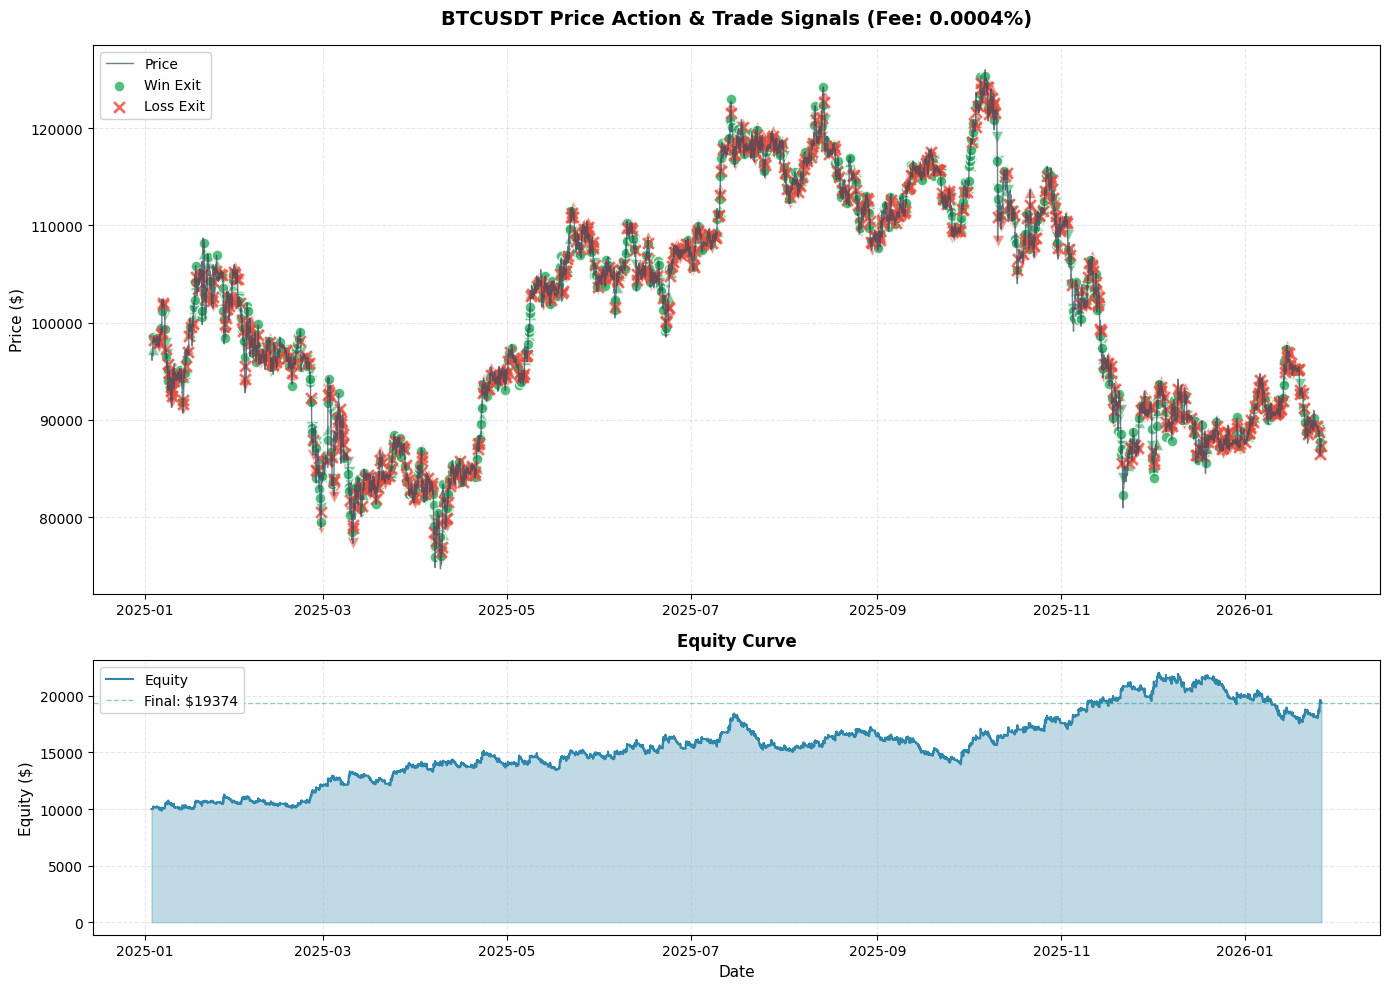


📊 Sample Trades (first 10):
            Exit Time   Type         Entry           Exit         PnL       Fee     Net PnL       Reason       Balance
0 2025-01-03 19:00:00   LONG  97241.598884   98527.970000  223.462380  0.068463  223.393917    Time Exit  10223.326347
1 2025-01-04 00:00:00   LONG  98592.020000   98174.170000  -61.422335  0.057725  -61.480060    Time Exit  10161.788317
2 2025-01-04 23:00:00   LONG  98313.227867   98417.250000   25.396386  0.096112   25.300274    Time Exit  10186.992581
3 2025-01-05 13:30:00  SHORT  97652.210000   97991.512385 -101.869926  0.117681 -101.987607    Stop Loss  10084.887700
4 2025-01-05 15:00:00  SHORT  97484.970000   97866.843135 -100.848877  0.103383 -100.952260    Stop Loss   9983.832461
5 2025-01-06 01:30:00   LONG  98357.424598   98121.240000  -52.231253  0.086796  -52.318049    Time Exit   9931.427406
6 2025-01-06 06:30:00   LONG  98804.133711   99484.840000  121.344739  0.070938  121.273801    Time Exit  10052.630755
7 2025-01-06 10:00:

In [16]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU (Giữ nguyên) ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM INDICATOR (FIXED) ---
def calculate_indicators(df):
    data = df.copy()
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_120'] = calc_atr(data['TR'], 120)
    data['ATR_63'] = calc_atr(data['TR'], 63)
    
    # Keltner Signal (63, 0.3)
    data['EMA_63'] = data['Close'].ewm(span=63, adjust=False).mean()
    data['KC_Sig_Upper'] = data['EMA_63'] + (0.3 * data['ATR_63'])
    data['KC_Sig_Lower'] = data['EMA_63'] - (0.3 * data['ATR_63'])
    
    # Keltner Entry (20, 1.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['KC_Ent_Upper'] = data['EMA_20'] + (1.5 * data['ATR_20'])
    data['KC_Ent_Lower'] = data['EMA_20'] - (1.5 * data['ATR_20'])
    
    # Range
    data['Range'] = data['High'] - data['Low']
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER (ADDED TRADING FEES) ---
class StrategyBacktester:
    def __init__(self, df, initial_balance=10000, trading_fee_pct=0.04):
        """
        Args:
            df: DataFrame với dữ liệu OHLCV và indicators
            initial_balance: Số vốn ban đầu
            trading_fee_pct: Phí giao dịch theo % (mặc định 0.04% cho Binance Futures maker)
        """
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        
        # Trading Fee
        self.trading_fee_pct = trading_fee_pct / 100  # Convert % to decimal
        self.total_fees_paid = 0
        
        # Params
        self.risk_pct = 0.01
        self.sl_coef = 1.7
        self.tp_coef = 4.4
        self.entry_mult = 0.2
        self.exit_bars = 8
        self.trailing_coef = 2.2
        self.trailing_activation_pct = 0.5
        
    def calculate_fee(self, price, qty):
        """Tính phí giao dịch"""
        return price * qty * self.trading_fee_pct
        
    def run(self):
        indices = self.df.index
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. Quản lý lệnh đang mở
            if self.position is not None:
                # Check Exit After Bars TRƯỚC
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_bars:
                    self.close_position(current_bar['Open'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue 

                # Check SL/TP
                if self.position == 'LONG':
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    elif current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    else:
                        # Trailing Stop
                        profit_pct = ((current_bar['Close'] - self.entry_price) / self.entry_price) * 100
                        if profit_pct >= self.trailing_activation_pct:
                            trail = self.trailing_coef * current_bar['ATR_120']
                            new_sl = current_bar['Close'] - trail
                            self.sl = max(self.sl, new_sl)
                                
                elif self.position == 'SHORT':
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    elif current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    else:
                        # Trailing Stop
                        profit_pct = ((self.entry_price - current_bar['Close']) / self.entry_price) * 100
                        if profit_pct >= self.trailing_activation_pct:
                            trail = self.trailing_coef * current_bar['ATR_120']
                            new_sl = current_bar['Close'] + trail
                            self.sl = min(self.sl, new_sl)

            # B. Pending Order
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                           self.pending_order['sl_dist'], self.pending_order['tp_dist'])
                        self.pending_order = None
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                           self.pending_order['sl_dist'], self.pending_order['tp_dist'])
                        self.pending_order = None

            # C. Signal Entry
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(idx)
                    continue
                
                close_prev = self.df.iloc[i-1]['Close']
                kc_sig_upper_prev = self.df.iloc[i-1]['KC_Sig_Upper']
                kc_sig_lower_prev = self.df.iloc[i-1]['KC_Sig_Lower']
                kc_ent_upper_shift3 = self.df.iloc[i-3]['KC_Ent_Upper']
                kc_ent_lower_shift3 = self.df.iloc[i-3]['KC_Ent_Lower']
                range_prev = self.df.iloc[i-1]['Range']
                atr_20_current = current_bar['ATR_20']
                
                sig_long = close_prev > kc_sig_upper_prev
                sig_short = close_prev < kc_sig_lower_prev
                
                if sig_long:
                    price = kc_ent_upper_shift3 + self.entry_mult * range_prev
                    self.pending_order = {
                        'type': 'BUY_STOP', 
                        'price': price, 
                        'sl_dist': self.sl_coef * atr_20_current, 
                        'tp_dist': self.tp_coef * atr_20_current, 
                        'expire_idx': i + 5
                    }
                elif sig_short and not sig_long:
                    price = kc_ent_lower_shift3 - self.entry_mult * range_prev
                    self.pending_order = {
                        'type': 'SELL_STOP', 
                        'price': price, 
                        'sl_dist': self.sl_coef * atr_20_current, 
                        'tp_dist': self.tp_coef * atr_20_current, 
                        'expire_idx': i + 5
                    }

            # D. Append Equity
            self.append_equity(idx)

    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        """Mở lệnh với phí giao dịch"""
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        self.sl = price - sl_dist if pos_type == 'LONG' else price + sl_dist
        self.tp = price + tp_dist if pos_type == 'LONG' else price - tp_dist
        
        risk_amt = self.balance * self.risk_pct
        dist_to_sl = abs(price - self.sl)
        self.qty = risk_amt / dist_to_sl if dist_to_sl > 0 else 0
        
        # Trừ phí mở lệnh
        entry_fee = self.calculate_fee(price, self.qty)
        self.balance -= entry_fee
        self.total_fees_paid += entry_fee

    def close_position(self, price, time_idx, reason):
        """Đóng lệnh với phí giao dịch"""
        # Tính P&L
        pnl = (price - self.entry_price) * self.qty if self.position == 'LONG' else (self.entry_price - price) * self.qty
        
        # Trừ phí đóng lệnh
        exit_fee = self.calculate_fee(price, self.qty)
        self.balance += pnl - exit_fee
        self.total_fees_paid += exit_fee
        
        self.trades.append({
            'Exit Time': time_idx, 
            'Type': self.position, 
            'Entry': self.entry_price,
            'Exit': price, 
            'PnL': pnl,
            'Fee': exit_fee,
            'Net PnL': pnl - exit_fee,
            'Reason': reason, 
            'Balance': self.balance
        })
        self.position = None
        self.qty = 0

# --- 4. HÀM TÍNH METRICS (UPDATED) ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance, total_fees):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['Net PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['Net PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor (dùng Net PnL)
    gross_profit = trades_df[trades_df['Net PnL'] > 0]['Net PnL'].sum()
    gross_loss = abs(trades_df[trades_df['Net PnL'] < 0]['Net PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'Total Fees Paid': total_fees,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol, fee_pct, price_data, trades_df):
    print("\n" + "="*60)
    print("="*60)
    print(f"     Final Equity: ${metrics['Final Equity']:.2f}")
    print(f"     Total Return: {metrics['Total Return']*100:.2f}%")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']*100:.2f}%")
    print(f"     Max Drawdown: {metrics['Max Drawdown']*100:.2f}%")
    print(f"           Sharpe: {metrics['Sharpe']:.2f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']*100:.2f}%")
    print(f"    Avg PnL/Trade: ${metrics['Avg PnL/Trade']:.2f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.2f}")
    print(f"   Total Fees Paid: ${metrics['Total Fees Paid']:.2f} ({fee_pct}%)")
    print("="*60)

    eq_df = metrics['equity_df']
    
    # Tạo figure với 2 subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), height_ratios=[2, 1])
    
    # --- SUBPLOT 1: Price Chart với Entry/Exit Points ---
    ax1.plot(price_data.index, price_data['Close'], linewidth=1, color='#34495e', alpha=0.7, label='Price')
    
    # Vẽ điểm entry và exit
    winning_trades = trades_df[trades_df['Net PnL'] > 0]
    losing_trades = trades_df[trades_df['Net PnL'] <= 0]
    
    # Entry points
    for _, trade in trades_df.iterrows():
        color = '#27AE60' if trade['Net PnL'] > 0 else '#E74C3C'
        marker = '^' if trade['Type'] == 'LONG' else 'v'
        ax1.scatter(trade['Exit Time'], trade['Entry'], marker=marker, 
                   color=color, s=80, alpha=0.6, edgecolors='white', linewidth=1)
    
    # Exit points (winning)
    ax1.scatter(winning_trades['Exit Time'], winning_trades['Exit'], 
               marker='o', color='#27AE60', s=60, alpha=0.8, 
               edgecolors='white', linewidth=1, label='Win Exit')
    
    # Exit points (losing)
    ax1.scatter(losing_trades['Exit Time'], losing_trades['Exit'], 
               marker='x', color='#E74C3C', s=60, alpha=0.8, 
               linewidth=2, label='Loss Exit')
    
    ax1.set_title(f"{symbol} Price Action & Trade Signals (Fee: {fee_pct}%)", 
                 fontsize=14, fontweight='bold', pad=15)
    ax1.set_ylabel('Price ($)', fontsize=11)
    ax1.legend(loc='upper left', framealpha=0.9)
    ax1.grid(True, linestyle='--', alpha=0.3)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    
    # --- SUBPLOT 2: Equity Curve ---
    ax2.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB', label='Equity')
    ax2.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    ax2.axhline(y=metrics['Final Equity'], color='#16A085', linestyle='--', 
                alpha=0.5, linewidth=1, label=f"Final: ${metrics['Final Equity']:.0f}")
    
    ax2.set_title("Equity Curve", fontsize=12, fontweight='bold', pad=10)
    ax2.set_xlabel('Date', fontsize=11)
    ax2.set_ylabel('Equity ($)', fontsize=11)
    ax2.legend(loc='upper left', framealpha=0.9)
    ax2.grid(True, linestyle='--', alpha=0.3)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "BTCUSDT"
    interval = "30m"
    start_date = "01/01/2025"
    end_date = "26/01/2026"
    
    # Cài đặt phí giao dịch (Binance Futures: 0.02% maker, 0.04% taker)
    TRADING_FEE = 0.0004  # 0.04% cho taker fee

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)

        bt = StrategyBacktester(df_calc, initial_balance=10000, trading_fee_pct=TRADING_FEE)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance, bt.total_fees_paid)
            print_report_and_plot(metrics, symbol, TRADING_FEE, df_calc, trades_df)
            
            # In thêm chi tiết 10 trades đầu
            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...

     Final Equity: $9449.30
     Total Return: -5.51%
    CAGR (approx): -5.27%
     Max Drawdown: -25.35%
           Sharpe: -0.08
           Trades: 550
          Winrate: 40.36%
    Avg PnL/Trade: $1.59
    Profit Factor: 1.04
   Total Fees Paid: $2849.29 (fee_rate=0.0004)


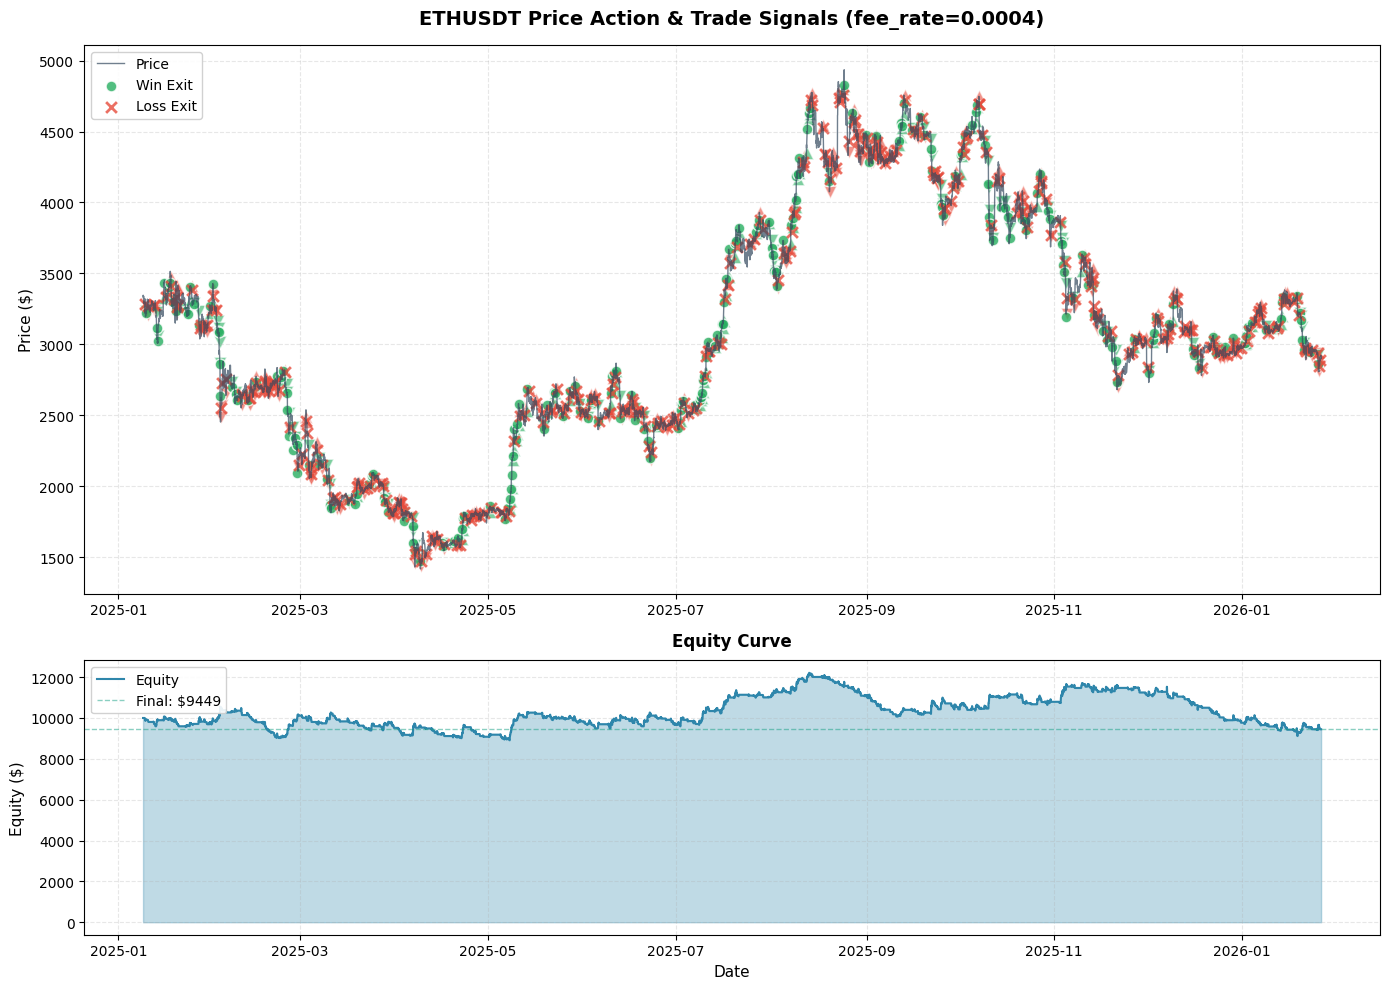


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit         PnL       Fee     Net PnL       Reason       Balance
0 2025-01-09 15:00:00  SHORT  3221.040000  3286.192890 -100.000000  2.017527 -102.017527    Stop Loss   9896.004946
1 2025-01-10 01:00:00  SHORT  3236.062915  3222.980000   18.487381  1.821749   16.665632    Time Exit   9910.841435
2 2025-01-10 17:00:00  SHORT  3210.190858  3267.778018  -99.108414  2.249559 -101.357973    Stop Loss   9807.273545
3 2025-01-12 14:00:00  SHORT  3245.565122  3278.658296  -98.072735  3.886566 -101.959301    Stop Loss   9701.466908
4 2025-01-13 00:00:00  SHORT  3239.981587  3273.865972  -97.014669  3.749373 -100.764042    Stop Loss   9596.992298
5 2025-01-13 10:00:00  SHORT  3227.124736  3115.512018  248.392742  2.773414  245.619328  Take Profit   9839.738855
6 2025-01-13 20:00:00  SHORT  3057.150000  3025.060000   58.236221  2.195925   56.040297    Time Exit   9893.559933
7 2025-01-15 23:00:00   LONG  3329.490000  

In [3]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU (Giữ nguyên) ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# --- 2. HÀM INDICATOR (ADD KC DÀI FILTER) ---
def calculate_indicators(df, trend_len=200, trend_mult=1.0):
    data = df.copy()
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)

    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    # ATR các period
    data['ATR_20']  = calc_atr(data['TR'], 20)
    data['ATR_120'] = calc_atr(data['TR'], 120)
    data['ATR_63']  = calc_atr(data['TR'], 63)

    # Keltner Signal (63, 0.3)
    data['EMA_63'] = data['Close'].ewm(span=63, adjust=False).mean()
    data['KC_Sig_Upper'] = data['EMA_63'] + (0.3 * data['ATR_63'])
    data['KC_Sig_Lower'] = data['EMA_63'] - (0.3 * data['ATR_63'])

    # Keltner Entry (20, 1.5)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['KC_Ent_Upper'] = data['EMA_20'] + (1.5 * data['ATR_20'])
    data['KC_Ent_Lower'] = data['EMA_20'] - (1.5 * data['ATR_20'])

    # Range
    data['Range'] = data['High'] - data['Low']

    # ===== KC DÀI (TREND FILTER) =====
    # EMA_trend + ATR_trend + KC_trend band
    data[f'EMA_{trend_len}'] = data['Close'].ewm(span=trend_len, adjust=False).mean()
    data[f'ATR_{trend_len}'] = calc_atr(data['TR'], trend_len)

    data['KC_Trend_Upper'] = data[f'EMA_{trend_len}'] + (trend_mult * data[f'ATR_{trend_len}'])
    data['KC_Trend_Lower'] = data[f'EMA_{trend_len}'] - (trend_mult * data[f'ATR_{trend_len}'])

    data.dropna(inplace=True)
    return data


# --- 3. BACKTESTER (ADD KC DÀI FILTER + FIX FEE INPUT) ---
class StrategyBacktester:
    def __init__(self, df, initial_balance=10000, fee_rate=0.0004,
                 trend_filter_mode="EMA", trend_len=200):
        """
        Args:
            df: DataFrame với OHLCV + indicators
            initial_balance: vốn ban đầu
            fee_rate: phí theo dạng DECIMAL (vd: 0.0004 = 0.04%)
            trend_filter_mode:
                - "EMA": chỉ long nếu Close > EMA_trend, short nếu Close < EMA_trend (lọc vừa)
                - "KC":  chỉ long nếu Close > KC_Trend_Upper, short nếu Close < KC_Trend_Lower (lọc mạnh)
                - "NONE": không dùng lọc
            trend_len: phải khớp với trend_len bạn dùng ở calculate_indicators()
        """
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = []
        self.trades = []
        self.position = None
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None

        # Fee
        self.fee_rate = float(fee_rate)
        self.total_fees_paid = 0.0

        # Trend filter
        self.trend_filter_mode = trend_filter_mode.upper()
        self.trend_len = trend_len

        # Params
        self.risk_pct = 0.01
        self.sl_coef = 1.7
        self.tp_coef = 4.4
        self.entry_mult = 0.2
        self.exit_bars = 8
        self.trailing_coef = 2.2
        self.trailing_activation_pct = 0.5

    def calculate_fee(self, price, qty):
        return price * qty * self.fee_rate

    def pass_trend_filter(self, i):
        """Trả về (allow_long, allow_short) theo trend_filter_mode."""
        if self.trend_filter_mode == "NONE":
            return True, True

        close_prev = self.df.iloc[i-1]['Close']

        if self.trend_filter_mode == "EMA":
            ema = self.df.iloc[i-1][f'EMA_{self.trend_len}']
            return (close_prev > ema), (close_prev < ema)

        if self.trend_filter_mode == "KC":
            ku = self.df.iloc[i-1]['KC_Trend_Upper']
            kl = self.df.iloc[i-1]['KC_Trend_Lower']
            return (close_prev > ku), (close_prev < kl)

        # fallback
        return True, True

    def run(self):
        indices = self.df.index
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]

            # A. Quản lý lệnh đang mở
            if self.position is not None:
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_bars:
                    self.close_position(current_bar['Open'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                if self.position == 'LONG':
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    elif current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    else:
                        profit_pct = ((current_bar['Close'] - self.entry_price) / self.entry_price) * 100
                        if profit_pct >= self.trailing_activation_pct:
                            trail = self.trailing_coef * current_bar['ATR_120']
                            new_sl = current_bar['Close'] - trail
                            self.sl = max(self.sl, new_sl)

                elif self.position == 'SHORT':
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    elif current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    else:
                        profit_pct = ((self.entry_price - current_bar['Close']) / self.entry_price) * 100
                        if profit_pct >= self.trailing_activation_pct:
                            trail = self.trailing_coef * current_bar['ATR_120']
                            new_sl = current_bar['Close'] + trail
                            self.sl = min(self.sl, new_sl)

            # B. Pending Order
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i,
                                           self.pending_order['sl_dist'], self.pending_order['tp_dist'])
                        self.pending_order = None
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i,
                                           self.pending_order['sl_dist'], self.pending_order['tp_dist'])
                        self.pending_order = None

            # C. Signal Entry (ADD TREND FILTER)
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(idx)
                    continue

                close_prev = self.df.iloc[i-1]['Close']
                kc_sig_upper_prev = self.df.iloc[i-1]['KC_Sig_Upper']
                kc_sig_lower_prev = self.df.iloc[i-1]['KC_Sig_Lower']
                kc_ent_upper_shift3 = self.df.iloc[i-3]['KC_Ent_Upper']
                kc_ent_lower_shift3 = self.df.iloc[i-3]['KC_Ent_Lower']
                range_prev = self.df.iloc[i-1]['Range']
                atr_20_current = current_bar['ATR_20']

                # Base signals
                base_long = close_prev > kc_sig_upper_prev
                base_short = close_prev < kc_sig_lower_prev

                # Trend gate
                allow_long, allow_short = self.pass_trend_filter(i)

                sig_long = base_long and allow_long
                sig_short = base_short and allow_short

                if sig_long:
                    price = kc_ent_upper_shift3 + self.entry_mult * range_prev
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': price,
                        'sl_dist': self.sl_coef * atr_20_current,
                        'tp_dist': self.tp_coef * atr_20_current,
                        'expire_idx': i + 5
                    }
                elif sig_short and not sig_long:
                    price = kc_ent_lower_shift3 - self.entry_mult * range_prev
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': price,
                        'sl_dist': self.sl_coef * atr_20_current,
                        'tp_dist': self.tp_coef * atr_20_current,
                        'expire_idx': i + 5
                    }

            # D. Append Equity
            self.append_equity(idx)

    def append_equity(self, idx):
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized

        self.equity_curve.append({'time': idx, 'equity': mark_to_market})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        self.sl = price - sl_dist if pos_type == 'LONG' else price + sl_dist
        self.tp = price + tp_dist if pos_type == 'LONG' else price - tp_dist

        risk_amt = self.balance * self.risk_pct
        dist_to_sl = abs(price - self.sl)
        self.qty = risk_amt / dist_to_sl if dist_to_sl > 0 else 0

        entry_fee = self.calculate_fee(price, self.qty)
        self.balance -= entry_fee
        self.total_fees_paid += entry_fee

    def close_position(self, price, time_idx, reason):
        pnl = (price - self.entry_price) * self.qty if self.position == 'LONG' else (self.entry_price - price) * self.qty

        exit_fee = self.calculate_fee(price, self.qty)
        self.balance += pnl - exit_fee
        self.total_fees_paid += exit_fee

        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Fee': exit_fee,
            'Net PnL': pnl - exit_fee,
            'Reason': reason,
            'Balance': self.balance
        })
        self.position = None
        self.qty = 0


# --- 4. METRICS (GIỮ NGUYÊN) ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance, total_fees):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]

    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0

    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()

    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['Net PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['Net PnL'].mean() if total_trades > 0 else 0

    gross_profit = trades_df[trades_df['Net PnL'] > 0]['Net PnL'].sum()
    gross_loss = abs(trades_df[trades_df['Net PnL'] < 0]['Net PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'Total Fees Paid': total_fees,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol, fee_rate, price_data, trades_df):
    print("\n" + "="*60)
    print("="*60)
    print(f"     Final Equity: ${metrics['Final Equity']:.2f}")
    print(f"     Total Return: {metrics['Total Return']*100:.2f}%")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']*100:.2f}%")
    print(f"     Max Drawdown: {metrics['Max Drawdown']*100:.2f}%")
    print(f"           Sharpe: {metrics['Sharpe']:.2f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']*100:.2f}%")
    print(f"    Avg PnL/Trade: ${metrics['Avg PnL/Trade']:.2f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.2f}")
    print(f"   Total Fees Paid: ${metrics['Total Fees Paid']:.2f} (fee_rate={fee_rate})")
    print("="*60)

    eq_df = metrics['equity_df']

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), height_ratios=[2, 1])

    ax1.plot(price_data.index, price_data['Close'], linewidth=1, color='#34495e', alpha=0.7, label='Price')

    winning_trades = trades_df[trades_df['Net PnL'] > 0]
    losing_trades = trades_df[trades_df['Net PnL'] <= 0]

    for _, trade in trades_df.iterrows():
        color = '#27AE60' if trade['Net PnL'] > 0 else '#E74C3C'
        marker = '^' if trade['Type'] == 'LONG' else 'v'
        ax1.scatter(trade['Exit Time'], trade['Entry'], marker=marker,
                    color=color, s=80, alpha=0.6, edgecolors='white', linewidth=1)

    ax1.scatter(winning_trades['Exit Time'], winning_trades['Exit'],
                marker='o', color='#27AE60', s=60, alpha=0.8,
                edgecolors='white', linewidth=1, label='Win Exit')

    ax1.scatter(losing_trades['Exit Time'], losing_trades['Exit'],
                marker='x', color='#E74C3C', s=60, alpha=0.8,
                linewidth=2, label='Loss Exit')

    ax1.set_title(f"{symbol} Price Action & Trade Signals (fee_rate={fee_rate})",
                  fontsize=14, fontweight='bold', pad=15)
    ax1.set_ylabel('Price ($)', fontsize=11)
    ax1.legend(loc='upper left', framealpha=0.9)
    ax1.grid(True, linestyle='--', alpha=0.3)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

    ax2.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#2E86AB', label='Equity')
    ax2.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#2E86AB')
    ax2.axhline(y=metrics['Final Equity'], color='#16A085', linestyle='--',
                alpha=0.5, linewidth=1, label=f"Final: ${metrics['Final Equity']:.0f}")

    ax2.set_title("Equity Curve", fontsize=12, fontweight='bold', pad=10)
    ax2.set_xlabel('Date', fontsize=11)
    ax2.set_ylabel('Equity ($)', fontsize=11)
    ax2.legend(loc='upper left', framealpha=0.9)
    ax2.grid(True, linestyle='--', alpha=0.3)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

    plt.tight_layout()
    plt.show()


# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "26/01/2026"

    # fee_rate dạng DECIMAL: 0.0004 = 0.04%
    FEE_RATE = 0.0004

    # ===== TREND FILTER SETTINGS =====
    TREND_LEN = 200
    TREND_MULT = 1.0
    TREND_FILTER_MODE = "EMA"   # "EMA" (lọc vừa) | "KC" (lọc mạnh) | "NONE"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw, trend_len=TREND_LEN, trend_mult=TREND_MULT)

        bt = StrategyBacktester(
            df_calc,
            initial_balance=10000,
            fee_rate=FEE_RATE,
            trend_filter_mode=TREND_FILTER_MODE,
            trend_len=TREND_LEN
        )
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance, bt.total_fees_paid)
            print_report_and_plot(metrics, symbol, FEE_RATE, df_calc, trades_df)

            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")
